# BUSI-CAD: Deep Learning for Breast Ultrasound Segmentation and Classification

BUSI-CAD explores two complementary tasks in breast ultrasound analysis: locating lesions through pixel-level segmentation and classifying images as benign, malignant, or normal.

The project brings together a custom U-Net, transfer learning with ResNet-50, image enhancement, augmentation, class-weighted optimization, and visual analysis of model predictions.

## Project highlights

- **Lesion segmentation:** implemented a U-Net with skip connections, batch normalization, and dropout, trained with a combined binary cross-entropy and Dice objective.
- **Transfer learning:** adapted an ImageNet-initialized ResNet-50 for three-class ultrasound classification.
- **Data preparation:** incorporated ultrasound image enhancement for segmentation and training-set augmentation for classification.
- **Class imbalance:** combined frequency-based class weights with additional class-specific weighting.
- **Prediction analysis:** implemented Grad-CAM visualization and repeated stochastic segmentation predictions.

## Results at a glance

| Task | Recorded validation result |
|---|---|
| Classification | **84.10% peak accuracy** on 195 images |
| Classification | **0.8296 macro F1** at the peak-accuracy epoch |
| Segmentation | **0.6817 final soft Dice** |

The segmentation and classification models form separate experimental workflows. Together, they demonstrate model development and evaluation at both the pixel and image levels.

## Notebook guide

1. Environment and dataset access
2. Dataset inspection
3. Image enhancement
4. U-Net segmentation
5. Stochastic prediction analysis
6. ResNet-50 classification
7. Grad-CAM visualization
8. Conclusions and next steps

## 1. Environment and dataset access

The project uses **TensorFlow/Keras** for model development, **OpenCV** and **Pillow** for image processing, **scikit-learn** for data splitting and evaluation, and **Matplotlib** for visualization.

The original workflow runs in Google Colab and retrieves the BUSI dataset through Kaggle.

**Dataset:** [Breast Ultrasound Images Dataset](https://www.kaggle.com/datasets/aryashah2k/breast-ultrasound-images-dataset)

The setup cell downloads and extracts the data into `Dataset_BUSI_with_GT`, containing the `benign`, `malignant`, and `normal` class directories.

To recreate the download step in Colab, supply your own `kaggle.json` credentials when prompted. Credentials should remain outside the repository. The notebook's saved results and figures can be viewed without running this step.

In [2]:
!pip install -q kaggle
from google.colab import files

files.upload()

!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json
!kaggle datasets download -d aryashah2k/breast-ultrasound-images-dataset
!unzip -q breast-ultrasound-images-dataset.zip


Saving kaggle.json to kaggle (1).json
Dataset URL: https://www.kaggle.com/datasets/aryashah2k/breast-ultrasound-images-dataset
License(s): CC0-1.0
breast-ultrasound-images-dataset.zip: Skipping, found more recently modified local copy (use --force to force download)
replace Dataset_BUSI_with_GT/benign/benign (1).png? [y]es, [n]o, [A]ll, [N]one, [r]ename: A


In [3]:
import os

import cv2
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from PIL import Image
from sklearn.metrics import f1_score, precision_score, recall_score
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input
from tensorflow.keras.callbacks import Callback, ModelCheckpoint
from tensorflow.keras.layers import BatchNormalization, Dense, Dropout, Flatten, Input
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.utils import to_categorical


## 2. Dataset inspection

The dataset contains **780 ultrasound images** spanning three diagnostic categories, with corresponding segmentation masks.

| Label | Class | Modeling role |
|---|---|---|
| 0 | Benign | Lesion segmentation and image classification |
| 1 | Malignant | Lesion segmentation and image classification |
| 2 | Normal | Background-only segmentation targets and image classification |

A shared image-and-mask cache supports both modeling workflows and avoids repeatedly loading the same files.

The preview below displays representative inputs from each class alongside their annotation masks. This provides an initial visual check of the image content, class labels, and segmentation targets before model development.

For this experiment, the loader uses each image's primary `_mask.png` annotation.

/tmp/ipython-input-3575686043.py:27: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  image = Image.fromarray(image, 'RGB')


Dataset shape: (5, 224, 224, 3)
Masks shape: (5, 224, 224)
Labels shape: (5,)


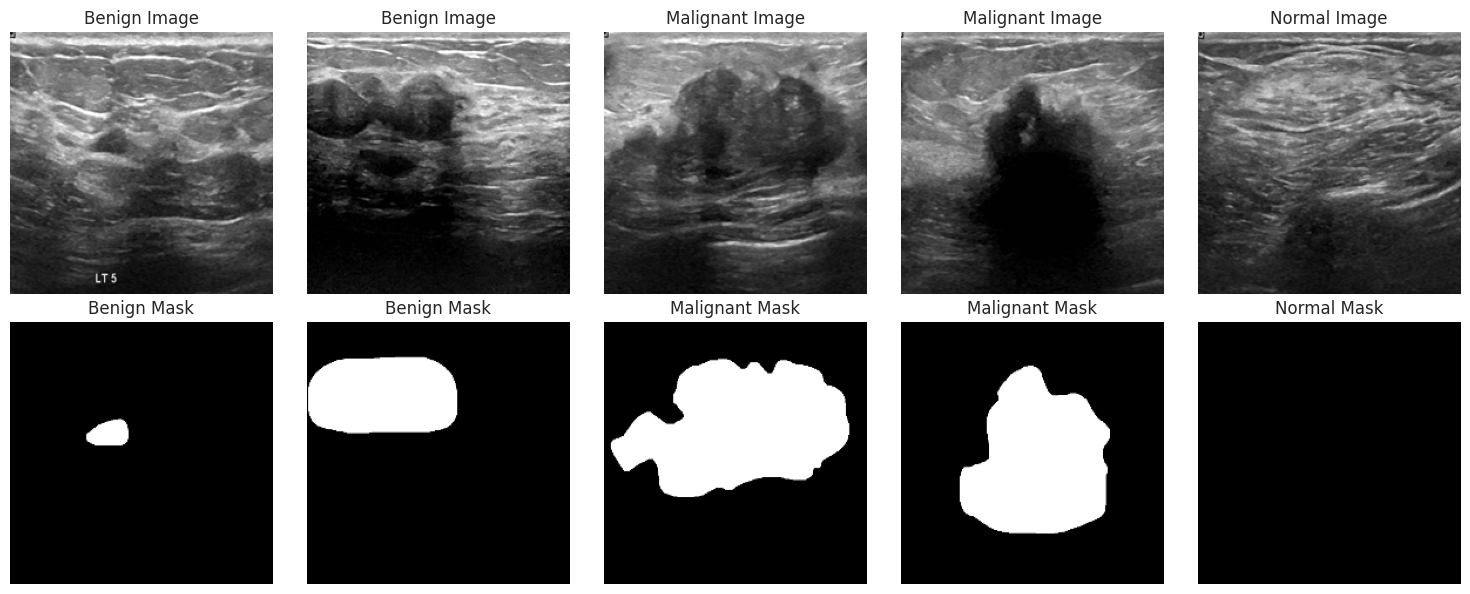

In [10]:
DATASET_DIRECTORY = "Dataset_BUSI_with_GT"
IMAGE_SIZE = 224
CLASS_NAMES = {0: "Benign", 1: "Malignant", 2: "Normal"}
CLASS_FOLDERS = {0: "benign", 1: "malignant", 2: "normal"}

# Cache each image and its corresponding mask once for reuse throughout the notebook.
raw_image_cache = {}
raw_image_index = {}

for folder in CLASS_FOLDERS.values():
    folder_path = os.path.join(DATASET_DIRECTORY, folder)
    cached_entries = []

    for image_name in os.listdir(folder_path):
        if "_mask" in image_name:
            continue

        parts = image_name.split(".")
        is_classification_image = len(parts) > 1 and parts[1] == "png"
        if not image_name.endswith(".png") and not is_classification_image:
            continue

        image_path = os.path.join(folder_path, image_name)
        image_bgr = cv2.imread(image_path)
        mask_name = image_name.replace(".png", "_mask.png")
        mask_path = os.path.join(folder_path, mask_name)
        mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

        entry = {
            "name": image_name,
            "image_bgr": image_bgr,
            "mask": mask,
        }
        cached_entries.append(entry)
        raw_image_index[(folder, image_name)] = entry

    raw_image_cache[folder] = cached_entries


def load_images_with_masks(image_folder, label_value, max_images=2, size=IMAGE_SIZE):
    """Return resized images and masks from the shared cache."""
    folder = image_folder.strip("/\\")
    image_files = [
        entry
        for entry in raw_image_cache[folder]
        if entry["name"].endswith(".png") and "_mask" not in entry["name"]
    ]

    if max_images is not None:
        image_files = image_files[:max_images]

    images = []
    masks = []
    labels = []

    for entry in image_files:
        image_bgr = entry["image_bgr"]
        mask = entry["mask"]

        if image_bgr is not None:
            image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
            image = Image.fromarray(image_rgb, "RGB")
            image = image.resize((size, size))
            image = np.array(image)

            if mask is not None:
                mask = cv2.resize(mask, (size, size))
                images.append(image)
                masks.append(mask)
                labels.append(label_value)

    return images, masks, labels


benign_images, benign_masks, benign_labels = load_images_with_masks(
    "benign/", 0, max_images=2
)
malignant_images, malignant_masks, malignant_labels = load_images_with_masks(
    "malignant/", 1, max_images=2
)
normal_images, normal_masks, normal_labels = load_images_with_masks(
    "normal/", 2, max_images=1
)

preview_images = np.array(benign_images + malignant_images + normal_images)
preview_masks = np.array(benign_masks + malignant_masks + normal_masks)
preview_labels = np.array(benign_labels + malignant_labels + normal_labels)

print("Dataset shape:", preview_images.shape)
print("Masks shape:", preview_masks.shape)
print("Labels shape:", preview_labels.shape)

plt.figure(figsize=(15, 6))
for i in range(5):
    plt.subplot(2, 5, i + 1)
    plt.imshow(preview_images[i])
    plt.title(f"{CLASS_NAMES[preview_labels[i]]} Image")
    plt.axis("off")

    plt.subplot(2, 5, i + 6)
    plt.imshow(preview_masks[i], cmap="gray")
    plt.title(f"{CLASS_NAMES[preview_labels[i]]} Mask")
    plt.axis("off")

plt.tight_layout()
plt.show()


## 3. Ultrasound image enhancement

Ultrasound images can exhibit speckle noise and limited contrast, making lesion boundaries difficult to distinguish. The segmentation workflow explores a three-stage enhancement pipeline:

1. **Bilateral filtering** to smooth local intensity variation while retaining edges.
2. **Histogram equalization** to redistribute global image contrast.
3. **Contrast-limited adaptive histogram equalization (CLAHE)** to enhance local contrast.

The comparison below illustrates the transformation on a malignant-class image.

This preprocessing is applied to the segmentation inputs. The classification experiment uses a separate resized-image pipeline. The example demonstrates the visual effect of enhancement; its contribution to predictive performance was not isolated through an ablation study.

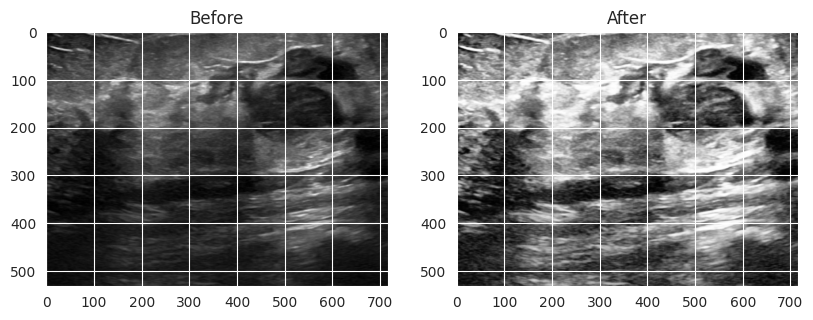

In [12]:
example_image_bgr = raw_image_index[("malignant", "malignant (57).png")]["image_bgr"]
if example_image_bgr is None:
    raise ValueError("Could not load the example image from the shared cache.")

img = cv2.cvtColor(example_image_bgr, cv2.COLOR_BGR2GRAY)

plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.imshow(img, cmap="gray")
plt.title("Before")

bilat_filtered = cv2.bilateralFilter(img, 3, 75, 75)
hist_eq = cv2.equalizeHist(bilat_filtered)
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
clahe_enhanced = clahe.apply(hist_eq)

plt.subplot(1, 3, 2)
plt.imshow(clahe_enhanced, cmap="gray")
plt.title("After")

plt.show()


## 4. Lesion segmentation with U-Net

The segmentation model learns to assign a lesion probability to each pixel. Its U-Net architecture combines an encoder that captures image context with a decoder that reconstructs spatial detail. Skip connections carry higher-resolution features between matching encoder and decoder stages.

### Model configuration

| Component | Configuration |
|---|---|
| Input | 256 × 256 enhanced images |
| Channels | Grayscale signal replicated across three channels |
| Encoder–decoder depth | Four downsampling and upsampling stages |
| Initial filters | 16 |
| Feature blocks | Convolution, batch normalization, and ReLU |
| Regularization | Dropout at a rate of 0.07 |
| Output | Single-channel sigmoid probability map |
| Optimizer | Adam |
| Training | 50 epochs |
| Data split | 80% training / 20% validation |

### Learning objective

The model combines **binary cross-entropy** with **soft Dice loss**, using equal weights. This objective incorporates both pixel-level classification and overlap between predicted and annotated lesion regions.

### Evaluation

Training curves track loss, pixel accuracy, and soft Dice on both training and validation data.

The implemented Dice metric measures overlap using continuous prediction probabilities aggregated within each batch. Pixel accuracy provides a complementary measure, while Dice focuses more directly on segmentation overlap.

The image-level split uses `random_state=42`.

/tmp/ipython-input-2241116102.py:29: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  image = Image.fromarray(image, 'RGB')


Epoch 1/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 54s 1s/step - accuracy: 0.6624 - dice_coefficient: 0.1429 - loss: 0.7411 - val_accuracy: 0.0759 - val_dice_coefficient: 0.1224 - val_loss: 269.2828
Epoch 2/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 46s 345ms/step - accuracy: 0.9119 - dice_coefficient: 0.1830 - loss: 0.6007 - val_accuracy: 0.0668 - val_dice_coefficient: 0.1213 - val_loss: 958.4918
Epoch 3/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 9s 481ms/step - accuracy: 0.9259 - dice_coefficient: 0.2938 - loss: 0.5089 - val_accuracy: 0.0703 - val_dice_coefficient: 0.1217 - val_loss: 117.3345
Epoch 4/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 8s 354ms/step - accuracy: 0.9353 - dice_coefficient: 0.3395 - loss: 0.4607 - val_accuracy: 0.2367 - val_dice_coefficient: 0.1390 - val_loss: 11.4127
Epoch 5/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 10s 338ms/step - accuracy: 0.9391 - dice_coefficient: 0.3838 - loss: 0.4229 - val_accuracy: 0.4675 - val_dice_coefficient: 0.1619 - val_loss: 4.9593
Epoch 6/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 10s 328ms/step - accuracy

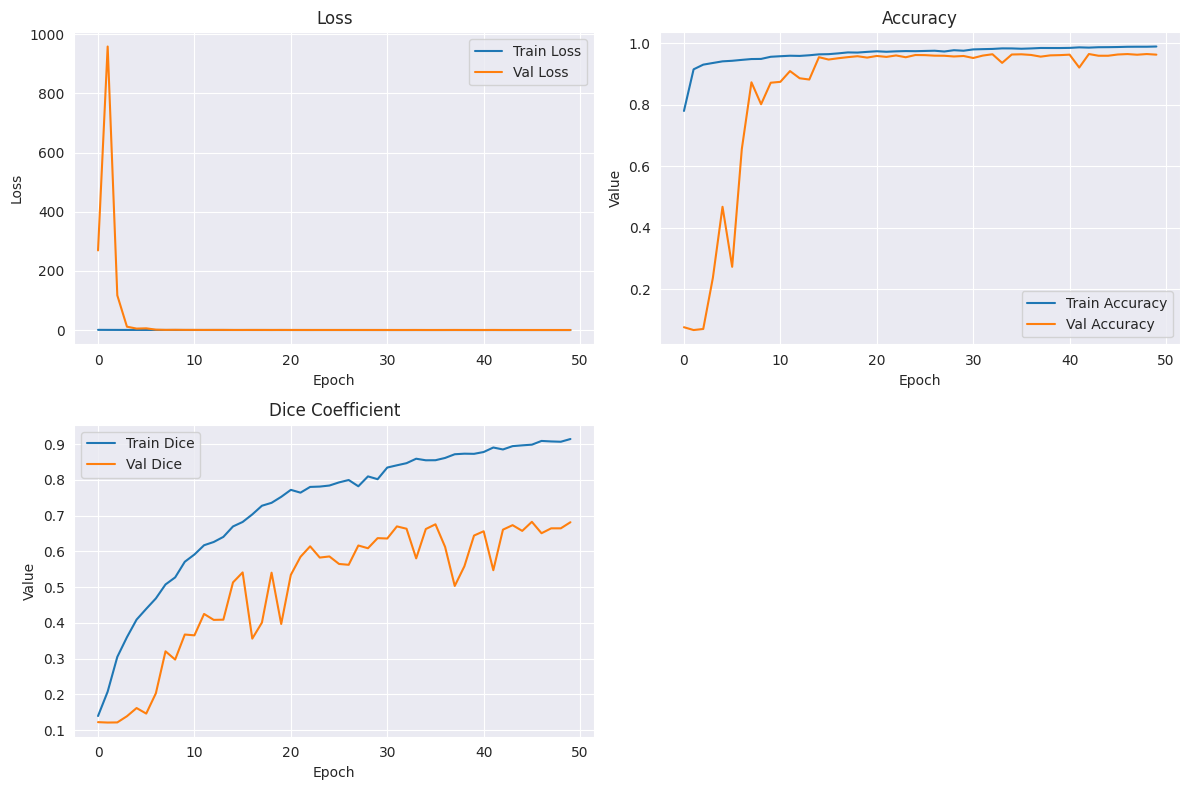

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step - accuracy: 0.9611 - dice_coefficient: 0.6772 - loss: 0.2523
Validation Loss: 0.24647414684295654
Validation Accuracy: 0.9622047543525696
Validation Dice Coefficient: 0.6817429065704346
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step


In [23]:
train_frame = {"img": [], "mask": []}


def load_segmentation_data(frame_obj, image_size=256):
    all_images = []
    all_masks = []

    for label_value, folder in CLASS_FOLDERS.items():
        images, masks, _ = load_images_with_masks(
            folder,
            label_value,
            max_images=None,
            size=image_size,
        )
        all_images.extend(images)
        all_masks.extend(masks)

    for index in range(len(all_images)):
        try:
            image = all_images[index] / 255.0
            mask = all_masks[index] / 255.0

            if len(image.shape) == 3:
                gray = cv2.cvtColor(
                    (image * 255).astype(np.uint8),
                    cv2.COLOR_RGB2GRAY,
                )
            else:
                gray = (image * 255).astype(np.uint8)

            bilateral = cv2.bilateralFilter(gray, 3, 75, 75)
            histogram_equalized = cv2.equalizeHist(bilateral)
            clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
            enhanced = clahe.apply(histogram_equalized)

            enhanced_float = enhanced.astype(np.float32) / 255.0
            enhanced_image = np.stack((enhanced_float,) * 3, axis=-1)
            enhanced_image = cv2.resize(
                enhanced_image,
                (image_size, image_size),
            )

            mask = cv2.resize(
                mask,
                (image_size, image_size),
                interpolation=cv2.INTER_NEAREST,
            )
            mask = (mask > 0.5).astype(np.float32)

            frame_obj["img"].append(enhanced_image)
            frame_obj["mask"].append(mask)
        except Exception as error:
            print(f"Skipping image {index} due to error: {error}")

    return frame_obj


train_frame = load_segmentation_data(train_frame, image_size=256)

segmentation_images = np.array(train_frame["img"])
segmentation_masks = np.expand_dims(np.array(train_frame["mask"]), axis=-1)

seg_train_images, seg_val_images, seg_train_masks, seg_val_masks = train_test_split(
    segmentation_images,
    segmentation_masks,
    test_size=0.2,
    random_state=42,
)


def dice_coefficient(y_true, y_pred, smooth=1.0):
    """Calculate the Dice coefficient for segmentation predictions."""
    y_true_flat = tf.keras.backend.flatten(y_true)
    y_pred_flat = tf.keras.backend.flatten(y_pred)
    intersection = tf.keras.backend.sum(y_true_flat * y_pred_flat)
    return (2.0 * intersection + smooth) / (
        tf.keras.backend.sum(y_true_flat)
        + tf.keras.backend.sum(y_pred_flat)
        + smooth
    )


def dice_loss(y_true, y_pred):
    """Calculate one minus the Dice coefficient."""
    return 1 - dice_coefficient(y_true, y_pred)


def combined_bce_dice_loss(y_true, y_pred, alpha=0.5):
    """Combine binary cross-entropy and Dice loss."""
    binary_cross_entropy = tf.keras.losses.binary_crossentropy(y_true, y_pred)
    segmentation_dice_loss = dice_loss(y_true, y_pred)
    return alpha * binary_cross_entropy + (1 - alpha) * segmentation_dice_loss


def conv2d_block(input_tensor, num_filters, kernel_size=3, use_batch_norm=True):
    x = tf.keras.layers.Conv2D(
        filters=num_filters,
        kernel_size=(kernel_size, kernel_size),
        kernel_initializer="he_normal",
        padding="same",
    )(input_tensor)
    if use_batch_norm:
        x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Activation("relu")(x)

    x = tf.keras.layers.Conv2D(
        filters=num_filters,
        kernel_size=(kernel_size, kernel_size),
        kernel_initializer="he_normal",
        padding="same",
    )(x)
    if use_batch_norm:
        x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Activation("relu")(x)
    return x


def build_unet(input_image, num_filters=16, dropouts=0.1, use_batch_norm=True):
    conv1 = conv2d_block(
        input_image, num_filters * 1, kernel_size=3, use_batch_norm=use_batch_norm
    )
    pool1 = tf.keras.layers.MaxPooling2D((2, 2))(conv1)
    pool1 = tf.keras.layers.Dropout(dropouts)(pool1)

    conv2 = conv2d_block(
        pool1, num_filters * 2, kernel_size=3, use_batch_norm=use_batch_norm
    )
    pool2 = tf.keras.layers.MaxPooling2D((2, 2))(conv2)
    pool2 = tf.keras.layers.Dropout(dropouts)(pool2)

    conv3 = conv2d_block(
        pool2, num_filters * 4, kernel_size=3, use_batch_norm=use_batch_norm
    )
    pool3 = tf.keras.layers.MaxPooling2D((2, 2))(conv3)
    pool3 = tf.keras.layers.Dropout(dropouts)(pool3)

    conv4 = conv2d_block(
        pool3, num_filters * 8, kernel_size=3, use_batch_norm=use_batch_norm
    )
    pool4 = tf.keras.layers.MaxPooling2D((2, 2))(conv4)
    pool4 = tf.keras.layers.Dropout(dropouts)(pool4)

    conv5 = conv2d_block(
        pool4, num_filters * 16, kernel_size=3, use_batch_norm=use_batch_norm
    )

    up6 = tf.keras.layers.Conv2DTranspose(
        num_filters * 8, (3, 3), strides=(2, 2), padding="same"
    )(conv5)
    up6 = tf.keras.layers.concatenate([up6, conv4])
    up6 = tf.keras.layers.Dropout(dropouts)(up6)
    conv6 = conv2d_block(
        up6, num_filters * 8, kernel_size=3, use_batch_norm=use_batch_norm
    )

    up7 = tf.keras.layers.Conv2DTranspose(
        num_filters * 4, (3, 3), strides=(2, 2), padding="same"
    )(conv6)
    up7 = tf.keras.layers.concatenate([up7, conv3])
    up7 = tf.keras.layers.Dropout(dropouts)(up7)
    conv7 = conv2d_block(
        up7, num_filters * 4, kernel_size=3, use_batch_norm=use_batch_norm
    )

    up8 = tf.keras.layers.Conv2DTranspose(
        num_filters * 2, (3, 3), strides=(2, 2), padding="same"
    )(conv7)
    up8 = tf.keras.layers.concatenate([up8, conv2])
    up8 = tf.keras.layers.Dropout(dropouts)(up8)
    conv8 = conv2d_block(
        up8, num_filters * 2, kernel_size=3, use_batch_norm=use_batch_norm
    )

    up9 = tf.keras.layers.Conv2DTranspose(
        num_filters * 1, (3, 3), strides=(2, 2), padding="same"
    )(conv8)
    up9 = tf.keras.layers.concatenate([up9, conv1])
    up9 = tf.keras.layers.Dropout(dropouts)(up9)
    conv9 = conv2d_block(
        up9, num_filters * 1, kernel_size=3, use_batch_norm=use_batch_norm
    )

    output = tf.keras.layers.Conv2D(1, (1, 1), activation="sigmoid")(conv9)
    return tf.keras.Model(inputs=[input_image], outputs=[output])


segmentation_inputs = tf.keras.layers.Input((256, 256, 3))
segmentation_model = build_unet(segmentation_inputs, dropouts=0.07)

segmentation_model.compile(
    optimizer="Adam",
    loss=combined_bce_dice_loss,
    metrics=["accuracy", dice_coefficient],
)

segmentation_history = segmentation_model.fit(
    seg_train_images,
    seg_train_masks,
    epochs=50,
    verbose=1,
    validation_data=(seg_val_images, seg_val_masks),
)

plt.figure(figsize=(12, 8))
plt.subplot(2, 2, 1)
plt.plot(segmentation_history.history["loss"], label="Train Loss")
plt.plot(segmentation_history.history["val_loss"], label="Val Loss")
plt.title("Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.subplot(2, 2, 2)
plt.plot(segmentation_history.history["accuracy"], label="Train Accuracy")
plt.plot(segmentation_history.history["val_accuracy"], label="Val Accuracy")
plt.title("Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Value")
plt.legend()
plt.grid(True)

plt.subplot(2, 2, 3)
plt.plot(segmentation_history.history["dice_coefficient"], label="Train Dice")
plt.plot(segmentation_history.history["val_dice_coefficient"], label="Val Dice")
plt.title("Dice Coefficient")
plt.xlabel("Epoch")
plt.ylabel("Value")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

validation_loss, validation_accuracy, validation_dice = segmentation_model.evaluate(
    seg_val_images,
    seg_val_masks,
    verbose=1,
)
print(f"Validation Loss: {validation_loss}")
print(f"Validation Accuracy: {validation_accuracy}")
print(f"Validation Dice Coefficient: {validation_dice}")


def predict_batch(validation_frame, model, image_size=256):
    images = validation_frame["img"][0:16]
    masks = validation_frame["mask"][0:16]
    processed_images = np.array(images)
    predictions = model.predict(processed_images)
    return predictions, processed_images, masks


def plot_segmentation_predictions(image, predicted_mask, ground_truth):
    plt.figure(figsize=(9, 9))
    plt.subplot(1, 3, 1)
    plt.imshow(image)
    plt.title("Image")
    plt.subplot(1, 3, 2)
    plt.imshow(predicted_mask)
    plt.title("Predicted Mask")
    plt.subplot(1, 3, 3)
    plt.imshow(ground_truth)
    plt.title("Actual Mask")
    plt.show()


validation_frame = {
    "img": list(seg_val_images),
    "mask": list(seg_val_masks.squeeze(-1)),
}
predictions, processed_images, ground_truth_masks = predict_batch(
    validation_frame,
    segmentation_model,
)


### Segmentation results

The final-epoch model achieved the following results on the segmentation validation split:

| Metric | Recorded value |
|---|---|
| Soft Dice | **0.6817** |
| Pixel accuracy | **96.22%** |
| Combined loss | **0.2465** |

The learning curves provide a view of optimization and generalization across 50 epochs. The prediction examples complement these numerical metrics by allowing direct comparison between model outputs and annotated lesion regions.

These results establish a baseline for further development of the segmentation workflow. The training–validation gap motivates future experiments with regularization and validation-based checkpoint selection.

## 5. Exploring segmentation prediction variability

Beyond a single deterministic prediction, the notebook explores how segmentation outputs vary across repeated stochastic forward passes.

For each example, the implementation performs **20 forward passes** and calculates:

- The **mean predicted probability map**.
- The **pixel-wise variance** across predictions.

The saved figures compare the input image, mean prediction, ground-truth mask, and binary prediction error. Together, these views support qualitative inspection of lesion coverage and boundary disagreement.

**Reading the figures:** the final panel displays error relative to the ground truth. Prediction variance is calculated separately and is not shown in these saved panels.

**Implementation scope:** this exploratory version enables batch normalization alongside dropout during sampling and uses examples from the full dataset. A follow-up analysis will isolate dropout during inference and evaluate variance on held-out images.

/usr/local/lib/python3.12/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor_152']
Received: inputs=Tensor(shape=(5, 256, 256, 3))
  warnings.warn(msg)


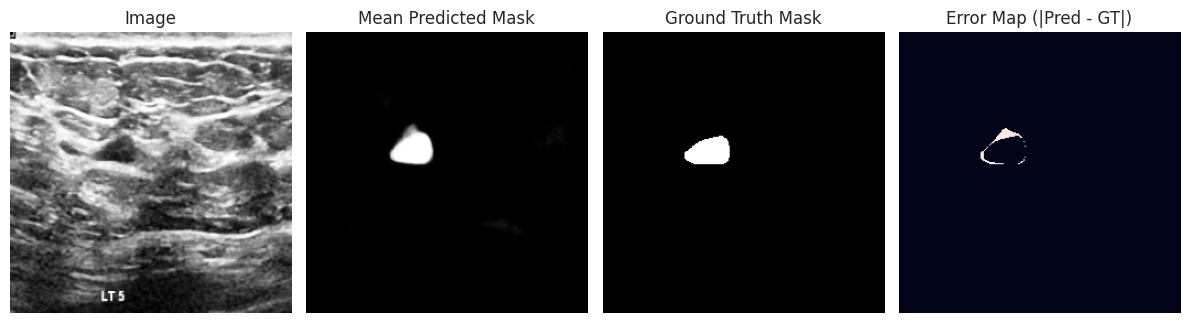

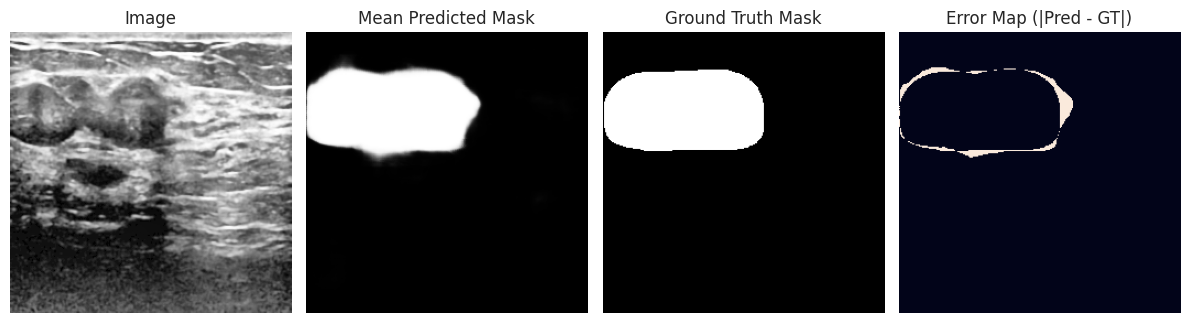

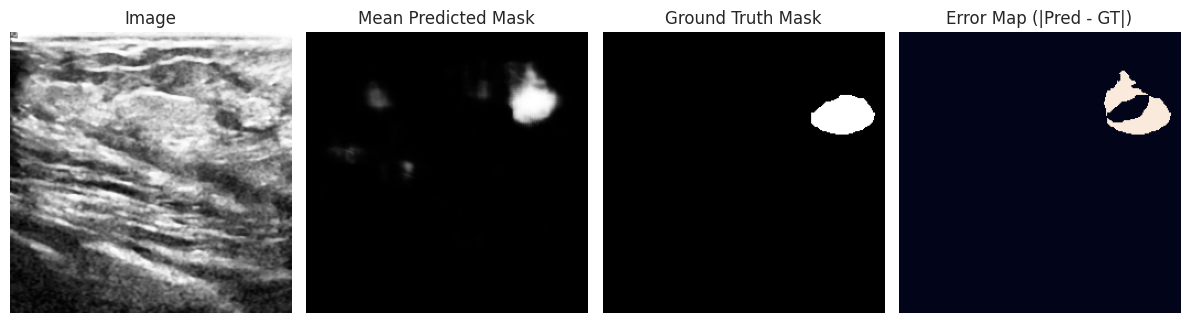

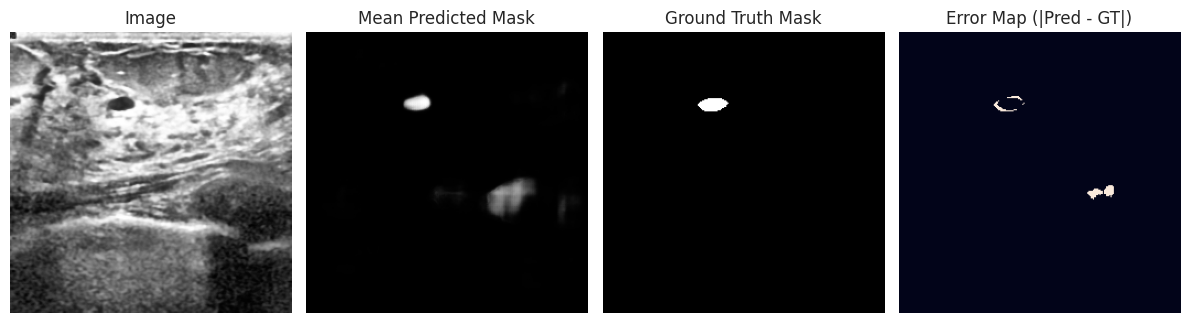

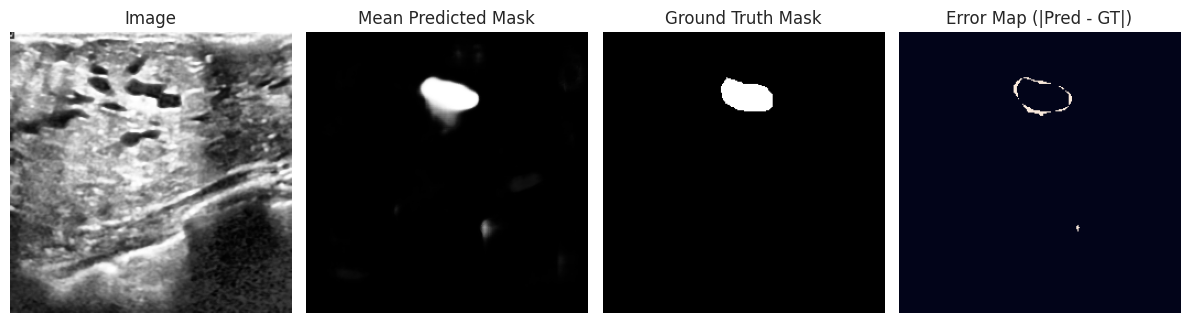

In [ ]:
def mc_dropout_predictions(model, image_batch, num_samples=20):
    """
    Compute mean predictions and variance from stochastic forward passes.

    Historical implementation:
        training=True activates dropout and trainable batch-normalization
        layers. These samples are not a dropout-only uncertainty estimate.

    Args:
        model: Trained segmentation model.
        image_batch: Images with shape (batch_size, height, width, channels).
        num_samples: Number of stochastic forward passes.

    Returns:
        Mean probability maps and pixel-wise prediction variance.
    """
    predictions = []

    for _ in range(num_samples):
        prediction = model(image_batch, training=True)
        predictions.append(prediction)

    predictions = np.array(predictions)
    mean_predictions = np.mean(predictions, axis=0)
    prediction_variance = np.var(predictions, axis=0)

    return mean_predictions, prediction_variance


def plot_with_uncertainty(image, mean_prediction, uncertainty, ground_truth):
    """
    Display the original experiment's prediction and error panels.

    The historical function name and signature are retained.
    The uncertainty argument contains prediction variance but is not
    displayed. The final panel shows ground-truth error, not uncertainty.
    """
    binary_prediction = (mean_prediction > 0.5).astype(np.float32)
    error_map = np.abs(
        binary_prediction.squeeze() - ground_truth.squeeze()
    )

    plt.figure(figsize=(12, 9))

    plt.subplot(1, 4, 1)
    plt.imshow(image)
    plt.title("Image")
    plt.axis("off")

    plt.subplot(1, 4, 2)
    plt.imshow(mean_prediction.squeeze(), cmap="gray")
    plt.title("Mean Predicted Mask")
    plt.axis("off")

    plt.subplot(1, 4, 3)
    plt.imshow(ground_truth.squeeze(), cmap="gray")
    plt.title("Ground Truth Mask")
    plt.axis("off")

    plt.subplot(1, 4, 4)
    plt.imshow(error_map)
    plt.title("Error Map (|Pred - GT|)")
    plt.axis("off")

    plt.tight_layout()
    plt.show()


# Preserve the original example selection: the first five entries
# from the complete preprocessed dataset, not a validation-only subset.
num_examples = 5
image_batch = np.array(train_frame["img"][:num_examples])
mask_batch = np.expand_dims(
    np.array(train_frame["mask"][:num_examples]),
    axis=-1,
)

mean_predictions, uncertainties = mc_dropout_predictions(
    segmentation_model,
    image_batch,
)

for i in range(num_examples):
    plot_with_uncertainty(
        image_batch[i],
        mean_predictions[i],
        uncertainties[i],
        mask_batch[i],
    )

## 6. Three-class classification with ResNet-50

The classification workflow adapts **ResNet-50 pretrained on ImageNet** to distinguish benign, malignant, and normal ultrasound images.

Transfer learning provides an initialized feature extractor, while selective fine-tuning and a task-specific classification head adapt the network to the ultrasound dataset.

### Data preparation

Images are resized to **224 × 224 pixels** and assigned one of three class labels.

| Subset | Number of source images |
|---|---|
| Training | 585 |
| Validation | 195 |

The split is created before augmentation, keeping validation images outside the augmentation pipeline.

In [4]:
def load_classification_images(image_folder, label_value):
    """Append cached images and their class labels to the classification dataset."""
    folder = image_folder.strip("/\\")

    for entry in raw_image_cache[folder]:
        image_name = entry["name"]
        if image_name.split(".")[1] == "png" and "_mask" not in image_name:
            image_bgr = entry["image_bgr"]
            if image_bgr is not None:
                # Preserve the original channel handling used in this notebook.
                image = Image.fromarray(image_bgr, "RGB")
                image = image.resize((IMAGE_SIZE, IMAGE_SIZE))
                classification_images.append(np.array(image))
                classification_labels.append(label_value)


classification_images = []
classification_labels = []

load_classification_images("benign/", 0)
load_classification_images("malignant/", 1)
load_classification_images("normal/", 2)

classification_images = np.array(classification_images)
classification_labels = np.array(classification_labels)

print("Dataset shape:", classification_images.shape)
print("Label shape:", classification_labels.shape)


/tmp/ipython-input-2814356353.py:9: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  image = Image.fromarray(image, 'RGB')


Dataset shape: (780, 224, 224, 3)
Label shape: (780,)


In [5]:
def custom_preprocessing(image):
    if image.dtype != np.uint8:
        image_uint8 = (image * 255).astype(np.uint8)
    else:
        image_uint8 = image

    if len(image_uint8.shape) == 3 and image_uint8.shape[2] == 3:
        gray = cv2.cvtColor(image_uint8, cv2.COLOR_RGB2GRAY)
    else:
        gray = image_uint8

    bilateral = cv2.bilateralFilter(gray, 3, 75, 75)
    histogram_equalized = cv2.equalizeHist(bilateral)

    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    enhanced = clahe.apply(histogram_equalized)
    enhanced_float = enhanced.astype(np.float32) / 255.0

    if len(image.shape) == 3 and image.shape[2] == 3:
        enhanced_float = np.stack((enhanced_float,) * 3, axis=-1)

    return enhanced_float


### Training-set augmentation

Random horizontal and vertical flips introduce orientation variation into the classification training data.

Two augmented passes expand the 585 source training images into a fixed array of **1,170 training samples**. Labels remain aligned with their corresponding transformed images.

Augmentation is performed only after splitting the dataset, so the 195 validation images remain separate from augmented training samples. The augmented array is generated once before model fitting.

In [ ]:
num_samples, height, width, channels = classification_images.shape
flattened_images = classification_images.reshape(num_samples, -1)

# Historical variable names are retained for compatibility with later cells.
# "test_images" and "test_labels" are used as validation data.
train_images, test_images, train_labels, test_labels = train_test_split(
    flattened_images,
    classification_labels,
    test_size=0.25,
    random_state=42,
)

train_images = train_images.reshape(-1, IMAGE_SIZE, IMAGE_SIZE, 3)

base_augmentation = ImageDataGenerator(
    horizontal_flip=True,
    vertical_flip=True,
    fill_mode="nearest",
)

base_augmentation.fit(train_images)

augmented_images = []
augmented_labels = []
augmentation_factor = 2

# Materialize two augmented passes before training.
# This preserves the original experiment's fixed augmented training array.
for image_batch, label_batch in base_augmentation.flow(
    train_images,
    train_labels,
    batch_size=len(train_images),
    shuffle=False,
):
    augmented_images.append(image_batch)
    augmented_labels.append(label_batch)

    if len(augmented_images) >= augmentation_factor:
        break

train_images = np.concatenate(augmented_images)
train_labels = np.concatenate(augmented_labels)

print("Shape of augmented images:", train_images.shape)
print("Shape of augmented labels:", train_labels.shape)

test_images = test_images.reshape(-1, IMAGE_SIZE, IMAGE_SIZE, 3)

Shape of augmented images: (1170, 224, 224, 3)
Shape of augmented labels: (1170,)


### Transfer learning and classification head

The model uses an ImageNet-initialized ResNet-50 backbone with global max pooling. The final 12 backbone layers are unfrozen for fine-tuning.

The task-specific head contains:

- Dropout with a rate of 0.5.
- A 512-unit dense layer with ReLU activation.
- Batch normalization.
- A second dropout layer.
- A three-class softmax output.

### Optimization and class weighting

| Setting | Value |
|---|---|
| Optimizer | Adam |
| Learning rate | 0.0005 |
| Loss | Categorical cross-entropy |
| Batch size | 32 |
| Epochs | 50 |
| Checkpoint criterion | Highest validation accuracy |

To address unequal class frequencies, balanced class weights are computed from the training labels. Additional experimental multipliers of **10 for malignant** and **4 for normal** increase those classes' contributions to the training objective.

### Evaluation beyond accuracy

A custom callback records **macro precision, macro recall, and macro F1** after each epoch. Macro averaging gives each class equal weight, complementing overall accuracy when class frequencies differ.

The best checkpoint is saved during training and restored afterward for subsequent analysis.

*Figure terminology: the saved plot's “F1 Score (Dice Coefficient)” panel reports macro classification F1. The segmentation section uses a separate soft Dice metric.*

Epoch 1/50
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 320ms/step - accuracy: 0.4422 - loss: 6.6623
Epoch 1: val_accuracy improved from -inf to 0.71795, saving model to best_model_weights.weights.h5
7/7 ━━━━━━━━━━━━━━━━━━━━ 9s 753ms/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 11s 195ms/step
Epoch 1: val_precision: 0.7265, val_recall: 0.6710, val_f1: 0.6359
37/37 ━━━━━━━━━━━━━━━━━━━━ 74s 1s/step - accuracy: 0.4438 - loss: 6.6304 - val_accuracy: 0.7179 - val_loss: 2.0875 - val_precision: 0.7265 - val_recall: 0.6710 - val_f1: 0.6359 - precision: 0.7307 - recall: 0.6482 - f1: 0.5947
Epoch 2/50
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 94ms/step - accuracy: 0.5971 - loss: 2.5206
Epoch 2: val_accuracy did not improve from 0.71795
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step
37/37 ━━━━━━━━━━━━━━━━━━━━ 3s 80ms/step
Epoch 2: val_precision: 0.7044, val_recall: 0.7508, val_f1: 0.6919
37/37 ━━━━━━━━━━━━━━━━━━━━ 26s 251ms/step - accuracy: 0.5974 - loss: 2.5163 - val_accuracy: 0.7128 - val_loss: 1.1262 - val_precision: 0.7044 - val_recall: 0.7

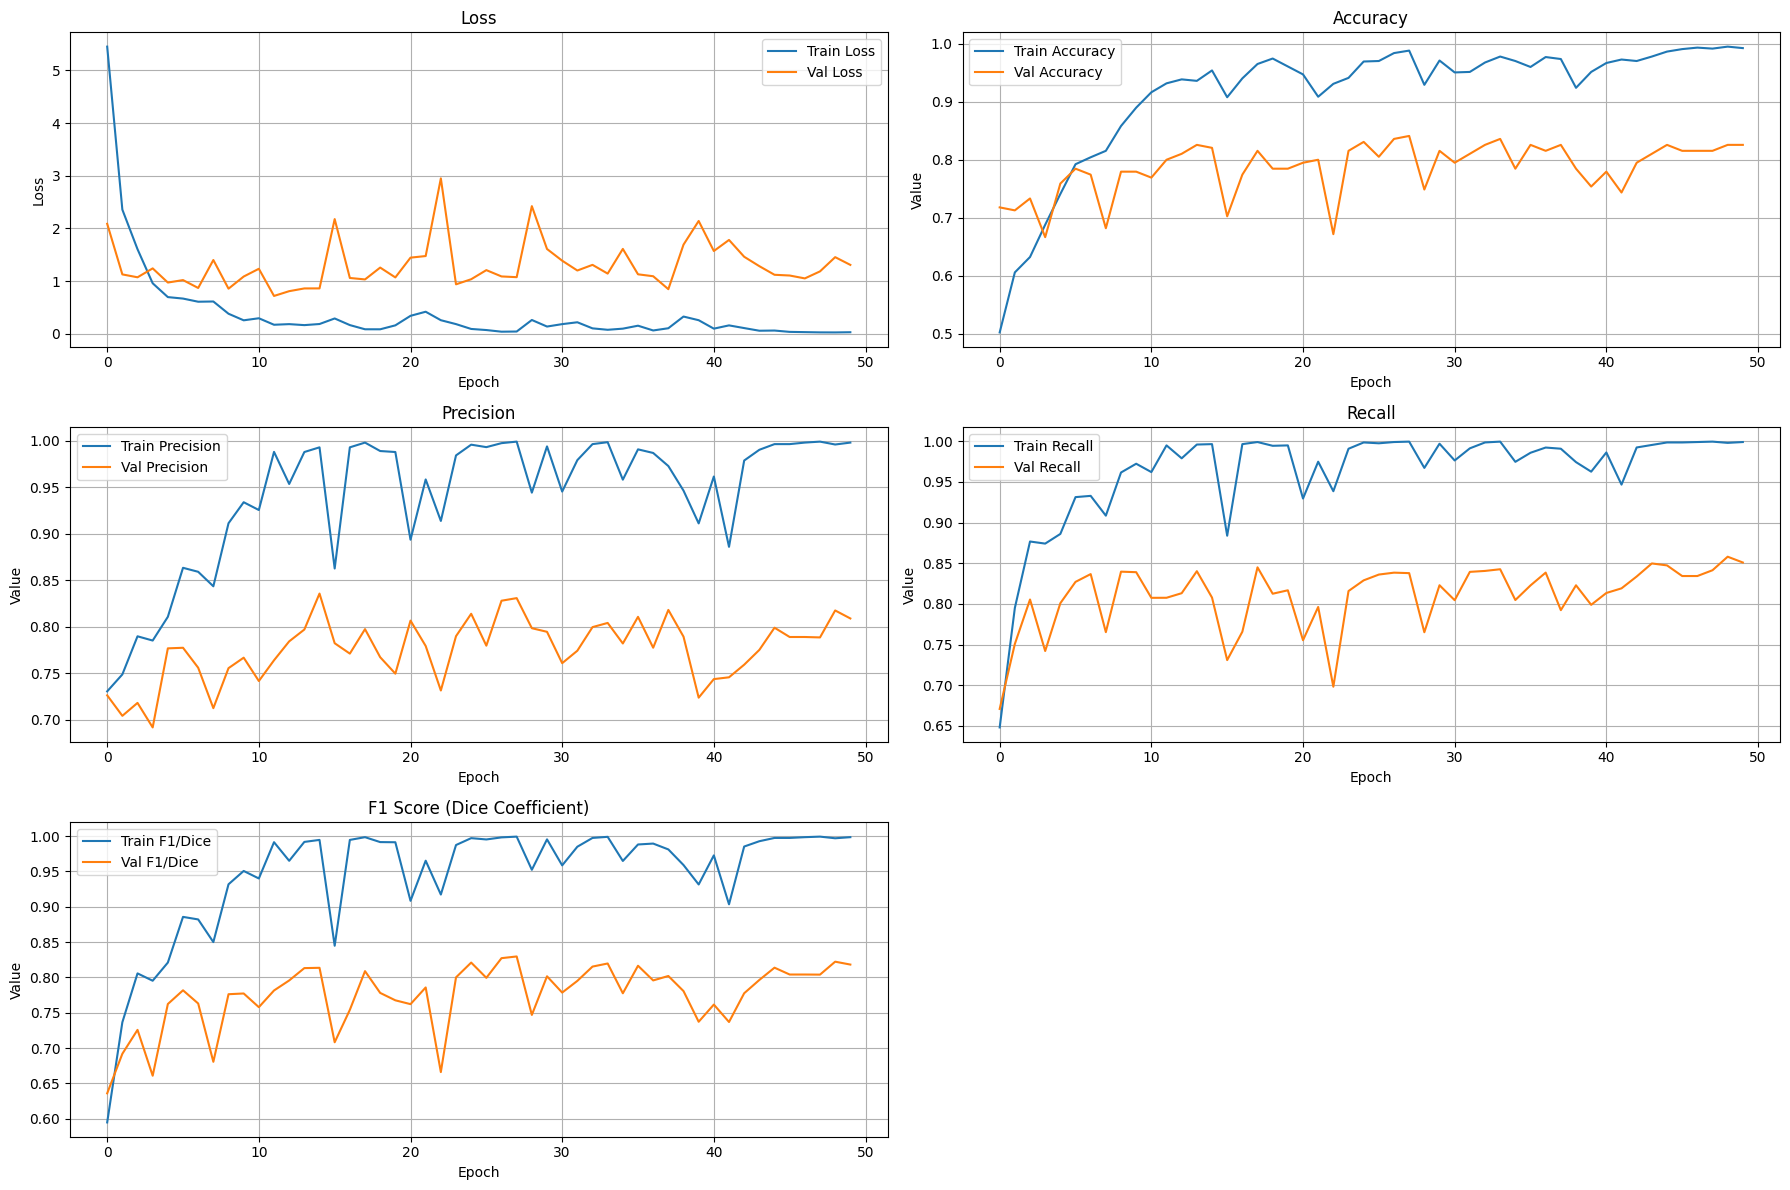

In [7]:
class CustomMetrics(Callback):
    def __init__(self, train_images, train_labels, test_images, test_labels):
        super().__init__()
        self.train_images = train_images
        self.train_labels = train_labels
        self.test_images = test_images
        self.test_labels = test_labels

    def on_epoch_end(self, epoch, logs=None):
        validation_predictions = self.model.predict(self.test_images)
        validation_predicted_labels = np.argmax(validation_predictions, axis=1)
        validation_true_labels = np.argmax(self.test_labels, axis=1)

        validation_precision = precision_score(
            validation_true_labels,
            validation_predicted_labels,
            average="macro",
        )
        validation_recall = recall_score(
            validation_true_labels,
            validation_predicted_labels,
            average="macro",
        )
        validation_f1 = f1_score(
            validation_true_labels,
            validation_predicted_labels,
            average="macro",
        )

        logs["val_precision"] = validation_precision
        logs["val_recall"] = validation_recall
        logs["val_f1"] = validation_f1

        train_predictions = self.model.predict(self.train_images)
        train_predicted_labels = np.argmax(train_predictions, axis=1)
        train_true_labels = np.argmax(self.train_labels, axis=1)

        train_precision = precision_score(
            train_true_labels,
            train_predicted_labels,
            average="macro",
        )
        train_recall = recall_score(
            train_true_labels,
            train_predicted_labels,
            average="macro",
        )
        train_f1 = f1_score(
            train_true_labels,
            train_predicted_labels,
            average="macro",
        )

        logs["precision"] = train_precision
        logs["recall"] = train_recall
        logs["f1"] = train_f1

        print(
            f"Epoch {epoch + 1}: val_precision: {validation_precision:.4f}, "
            f"val_recall: {validation_recall:.4f}, val_f1: {validation_f1:.4f}"
        )


INPUT_SHAPE = (224, 224, 3)
inputs = Input(shape=INPUT_SHAPE)

base_model = ResNet50(
    include_top=False,
    weights="imagenet",
    input_tensor=inputs,
    pooling="max",
    name="resnet50",
)

for layer in base_model.layers:
    layer.trainable = False

for layer in base_model.layers[-12:]:
    layer.trainable = True

x = base_model.output
x = Dropout(0.5)(x)
x = Flatten()(x)
x = Dense(512, activation="relu")(x)
x = BatchNormalization()(x)
x = Dropout(0.5)(x)
outputs = Dense(3, activation="softmax")(x)

classification_model = Model(inputs=inputs, outputs=outputs)
optimizer = Adam(learning_rate=0.0005)

classification_model.compile(
    optimizer=optimizer,
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)

if len(train_labels.shape) > 1 and train_labels.shape[1] > 1:
    train_label_ids = np.argmax(train_labels, axis=1)
else:
    train_label_ids = train_labels

class_labels = np.unique(train_label_ids)
class_weights = compute_class_weight(
    "balanced",
    classes=class_labels,
    y=train_label_ids,
)

class_weights[1] *= 10.0
class_weights[2] *= 4.0
class_weight = {i: weight for i, weight in enumerate(class_weights)}

if len(train_labels.shape) == 1 or train_labels.shape[1] != 3:
    train_labels = to_categorical(train_labels, num_classes=3)
    test_labels = to_categorical(test_labels, num_classes=3)

checkpoint_path = "best_model_weights.weights.h5"
checkpoint = ModelCheckpoint(
    checkpoint_path,
    monitor="val_accuracy",
    verbose=1,
    save_best_only=True,
    mode="max",
    save_weights_only=True,
)

custom_metrics = CustomMetrics(
    np.array(train_images),
    train_labels,
    np.array(test_images),
    test_labels,
)

classification_history = classification_model.fit(
    np.array(train_images),
    train_labels,
    batch_size=32,
    verbose=1,
    epochs=50,
    validation_data=(test_images, test_labels),
    shuffle=True,
    class_weight=class_weight,
    callbacks=[checkpoint, custom_metrics],
)

classification_model.load_weights(checkpoint_path)

plt.figure(figsize=(18, 12))

plt.subplot(3, 2, 1)
plt.plot(classification_history.history["loss"], label="Train Loss")
plt.plot(classification_history.history["val_loss"], label="Val Loss")
plt.title("Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.subplot(3, 2, 2)
plt.plot(classification_history.history["accuracy"], label="Train Accuracy")
plt.plot(classification_history.history["val_accuracy"], label="Val Accuracy")
plt.title("Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Value")
plt.legend()
plt.grid(True)

plt.subplot(3, 2, 3)
plt.plot(classification_history.history["precision"], label="Train Precision")
plt.plot(classification_history.history["val_precision"], label="Val Precision")
plt.title("Precision")
plt.xlabel("Epoch")
plt.ylabel("Value")
plt.legend()
plt.grid(True)

plt.subplot(3, 2, 4)
plt.plot(classification_history.history["recall"], label="Train Recall")
plt.plot(classification_history.history["val_recall"], label="Val Recall")
plt.title("Recall")
plt.xlabel("Epoch")
plt.ylabel("Value")
plt.legend()
plt.grid(True)

plt.subplot(3, 2, 5)
plt.plot(classification_history.history["f1"], label="Train F1/Dice")
plt.plot(classification_history.history["val_f1"], label="Val F1/Dice")
plt.title("F1 Score (Dice Coefficient)")
plt.xlabel("Epoch")
plt.ylabel("Value")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


### Classification results

The classifier reached its highest validation accuracy at **epoch 28**:

| Metric | Value |
|---|---|
| Validation accuracy | **84.10%** |
| Macro precision | **0.8309** |
| Macro recall | **0.8379** |
| Macro F1 | **0.8296** |
| Validation images | **195** |

All metrics above refer to the same epoch, providing a consistent view of the selected checkpoint's performance.

The combination of accuracy and macro-averaged metrics summarizes both overall classification performance and performance with equal weighting across the three classes.

## 7. Visual inspection with Grad-CAM

To complement numerical evaluation, the notebook implements **Gradient-weighted Class Activation Mapping (Grad-CAM)** using ResNet-50's final convolutional block, `conv5_block3_out`.

The visualization presents:

1. The original ultrasound image.
2. A class-specific activation heatmap.
3. The heatmap overlaid on the image.

This provides a way to inspect spatial regions associated with the model's selected class score and to investigate individual predictions.

### Preserved example

For `malignant (57).png`, the saved model output predicts **benign**. The heatmap therefore visualizes the benign class score. This example is retained as a case for prediction inspection rather than a successful classification example.

The original visualization applies ResNet preprocessing that differs from the classification training pipeline. Aligning these input transformations and regenerating the heatmap is a priority for the next revision. The current figure demonstrates the visualization implementation, but should not be used to establish lesion-localization performance.

1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step
Predicted class: Benign (Index: 0)
Prediction probabilities: [9.9724519e-01 1.8352574e-03 9.1951905e-04]


/tmp/ipython-input-268769234.py:73: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  jet = plt.cm.get_cmap("jet")


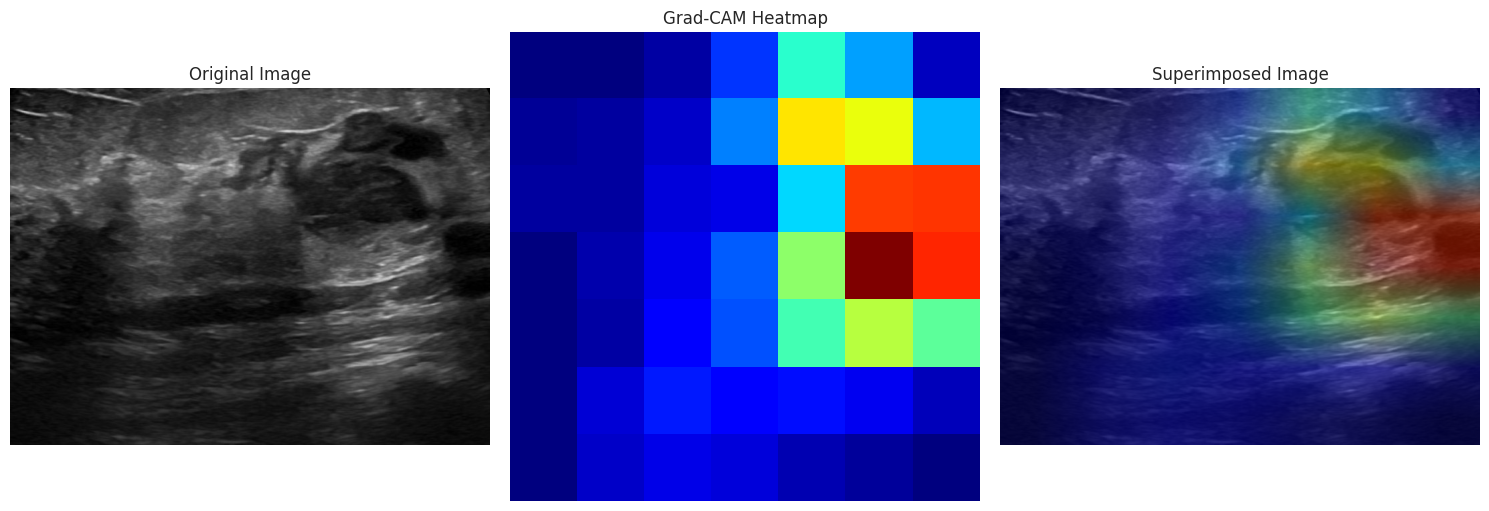

In [7]:
def make_gradcam_heatmap(
    image_array,
    model,
    last_conv_layer_name="conv5_block3_out",
    pred_index=None,
):
    """
    Generate a Grad-CAM heatmap for an image and a class index.

    Args:
        image_array: Preprocessed input image with shape (1, 224, 224, 3).
        model: Trained classification model.
        last_conv_layer_name: Name of the final convolutional layer.
        pred_index: Class index; None selects the predicted class.

    Returns:
        A two-dimensional Grad-CAM heatmap.
    """
    grad_model = tf.keras.models.Model(
        inputs=model.input,
        outputs=[
            model.get_layer(last_conv_layer_name).output,
            model.output,
        ],
    )

    with tf.GradientTape() as tape:
        convolution_outputs, predictions = grad_model(image_array)
        if pred_index is None:
            pred_index = tf.argmax(predictions[0])
        class_channel = predictions[:, pred_index]

    gradients = tape.gradient(class_channel, convolution_outputs)
    pooled_gradients = tf.reduce_mean(gradients, axis=(0, 1, 2))

    convolution_outputs = convolution_outputs[0]
    heatmap = convolution_outputs @ pooled_gradients[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0) / tf.math.reduce_max(heatmap)
    return heatmap.numpy()


def display_gradcam(original_image, heatmap, alpha=0.4):
    """Display the Grad-CAM heatmap and its overlay on the original image."""
    heatmap_uint8 = np.uint8(255 * heatmap)

    jet = plt.cm.get_cmap("jet")
    jet_colors = jet(np.arange(256))[:, :3]
    jet_heatmap = np.uint8(jet_colors[heatmap_uint8] * 255)
    jet_heatmap = cv2.resize(
        jet_heatmap,
        (original_image.shape[1], original_image.shape[0]),
    )
    superimposed_image = cv2.addWeighted(
        original_image,
        1 - alpha,
        jet_heatmap,
        alpha,
        0,
    )

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    axes[0].imshow(original_image)
    axes[0].set_title("Original Image")
    axes[0].axis("off")

    axes[1].imshow(heatmap_uint8, cmap="jet")
    axes[1].set_title("Grad-CAM Heatmap")
    axes[1].axis("off")

    axes[2].imshow(superimposed_image)
    axes[2].set_title("Superimposed Image")
    axes[2].axis("off")

    plt.tight_layout()
    plt.show()


gradcam_image_name = "malignant (57).png"
original_image_bgr = raw_image_index[("malignant", gradcam_image_name)]["image_bgr"]
if original_image_bgr is None:
    raise ValueError(f"Could not load image at: {gradcam_image_name}")

original_image = cv2.cvtColor(original_image_bgr, cv2.COLOR_BGR2RGB)
resized_image = cv2.resize(original_image, (IMAGE_SIZE, IMAGE_SIZE))
image_array = np.expand_dims(resized_image, axis=0).astype(np.float32)
image_array = preprocess_input(image_array)

classification_predictions = classification_model.predict(image_array)
predicted_class = np.argmax(classification_predictions[0])
classification_class_names = ["Benign", "Malignant", "Normal"]

print(
    f"Predicted class: {classification_class_names[predicted_class]} "
    f"(Index: {predicted_class})"
)
print(f"Prediction probabilities: {classification_predictions[0]}")

heatmap = make_gradcam_heatmap(
    image_array,
    classification_model,
    last_conv_layer_name="conv5_block3_out",
    pred_index=predicted_class,
)
display_gradcam(original_image, heatmap)


## 8. Conclusions and next steps

BUSI-CAD combines pixel-level lesion segmentation and image-level classification within one documented breast ultrasound project.

The work demonstrates:

- **Architecture development:** constructing a U-Net with encoder–decoder skip connections and a combined segmentation objective.
- **Transfer learning:** adapting and selectively fine-tuning ResNet-50 for a three-class task.
- **Data processing:** preparing paired images and masks, enhancing segmentation inputs, and augmenting classification training samples.
- **Training design:** applying class-weighted optimization, checkpoint selection, and custom metric tracking.
- **Model analysis:** examining learning curves, segmentation outputs, stochastic predictions, and class-specific activation maps.

The recorded experiments achieved **84.10% peak classification validation accuracy**, **0.8296 macro F1 at the same epoch**, and **0.6817 final segmentation validation soft Dice**.

### Development priorities

The next iteration will build on these results by:

1. Standardizing preprocessing across classifier training and visualization.
2. Refining mask preparation, including handling additional annotation masks where present.
3. Separating dropout sampling from batch-normalization updates and visualizing prediction variance.
4. Expanding evaluation with per-class classification results and per-image segmentation metrics.
5. Comparing preprocessing and class-weighting choices through controlled experiments.
6. Recording dependency versions, split assignments, and checkpoints to support reproducibility.

### Experimental scope

The current results use random image-level validation splits without stratification or patient grouping; they do not establish patient-independent or clinical performance. The original segmentation loader uses primary masks and includes an initial default-interpolation resize, which will be reviewed in the next iteration.

This edition preserves the original outputs. Planned improvements are described as future work and are not presented as completed experiments.